# **Import Requirements**

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler

In [24]:
df = pd.read_csv("../data/processed/credit_card_fe.csv")

In [25]:
df.info()
print()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   balance                           8950 non-null   float64
 1   balance_frequency                 8950 non-null   float64
 2   purchases                         8950 non-null   float64
 3   oneoff_purchases                  8950 non-null   float64
 4   installments_purchases            8950 non-null   float64
 5   cash_advance                      8950 non-null   float64
 6   purchases_frequency               8950 non-null   float64
 7   oneoff_purchases_frequency        8950 non-null   float64
 8   purchases_installments_frequency  8950 non-null   float64
 9   cash_advance_frequency            8950 non-null   float64
 10  cash_advance_trx                  8950 non-null   int64  
 11  purchases_trx                     8950 non-null   int64  
 12  credit_limit     

(8950, 18)

In [26]:
df.sample(5)

,balance,balance_frequency,purchases,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure,credit_utilization
6430,3312.514107,1.000000,0.00,0.0,0.00,830.921998,0.000000,0.0,0.000000,0.333333,5,0,6500.0,962.359607,861.467363,0.000000,12,0.509618
7306,284.433780,0.363636,212.92,0.0,212.92,0.000000,0.833333,0.0,0.833333,0.000000,0,15,1500.0,1202.791804,150.107024,0.000000,12,0.189623
4513,1541.743608,1.000000,0.00,0.0,0.00,118.974129,0.000000,0.0,0.000000,0.333333,5,0,1600.0,353.686721,428.150067,0.000000,12,0.963590
4647,884.230978,1.000000,0.00,0.0,0.00,611.764160,0.000000,0.0,0.000000,0.083333,2,0,1200.0,883.943797,216.195821,0.000000,12,0.736859
294,41.833264,1.000000,456.36,0.0,456.36,0.000000,1.000000,0.0,0.916667,0.000000,0,14,6000.0,370.996177,163.287618,0.333333,12,0.006972


In [27]:
skewness = df.skew().sort_values(ascending=False)

skewness

minimum_payments                    13.841597
oneoff_purchases                    10.045083
purchases                            8.144269
credit_utilization                   7.416991
installments_purchases               7.299120
payments                             5.907620
cash_advance_trx                     5.721298
cash_advance                         5.166609
purchases_trx                        4.630655
balance                              2.393386
prc_full_payment                     1.942820
cash_advance_frequency               1.828686
oneoff_purchases_frequency           1.535613
credit_limit                         1.522636
purchases_installments_frequency     0.509201
purchases_frequency                  0.060164
balance_frequency                   -2.023266
tenure                              -2.943017
dtype: float64

In [28]:
log_features = [
    'minimum_payments',
    'oneoff_purchases',
    'purchases',
    'installments_purchases',
    'payments',
    'cash_advance_trx',
    'cash_advance',
    'purchases_trx',
    'balance',
    'credit_limit'
]

for col in log_features:
  df[col] = np.log1p(df[col])

In [29]:
skewness_after = df.skew().sort_values(ascending=False)
skewness_after

credit_utilization                  7.416991
prc_full_payment                    1.942820
cash_advance_frequency              1.828686
oneoff_purchases_frequency          1.535613
cash_advance_trx                    0.940131
purchases_installments_frequency    0.509201
cash_advance                        0.262594
oneoff_purchases                    0.185854
purchases_frequency                 0.060164
purchases_trx                       0.032697
installments_purchases             -0.024981
credit_limit                       -0.101408
minimum_payments                   -0.489385
purchases                          -0.764492
balance                            -0.861021
payments                           -1.778312
balance_frequency                  -2.023266
tenure                             -2.943017
dtype: float64

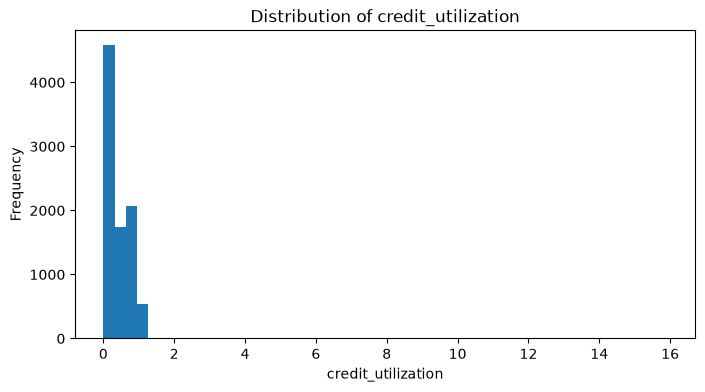

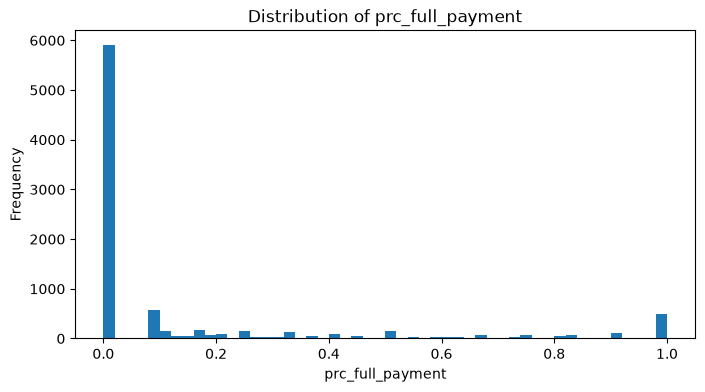

In [30]:
features = [
    'credit_utilization',
    'prc_full_payment',
]

for col in features:
    plt.figure(figsize=(8, 4))
    plt.hist(df[col], bins=50)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

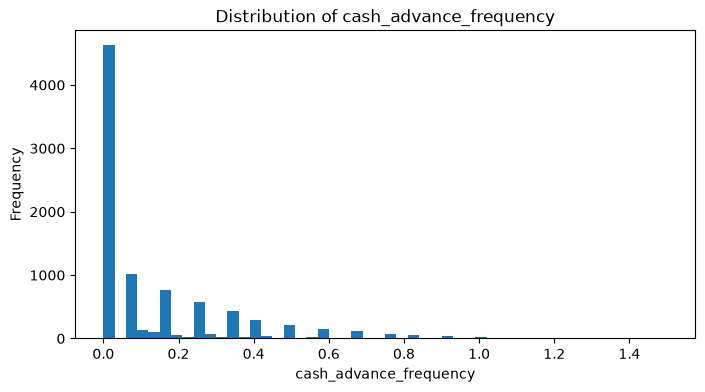

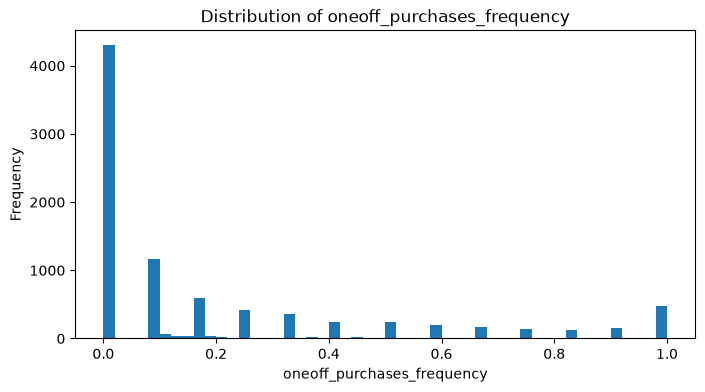

In [31]:
features = [
    'cash_advance_frequency',
    'oneoff_purchases_frequency'
]

for col in features:
    plt.figure(figsize=(8, 4))
    plt.hist(df[col], bins=50)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [32]:
df['credit_utilization'].describe()

count    8950.000000
mean        0.388884
std         0.389722
min         0.000000
25%         0.041494
50%         0.302720
75%         0.717571
max        15.909951
Name: credit_utilization, dtype: float64

In [33]:
df['credit_utilization'].quantile(
    [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.995, 0.999, 1]
)

0.000     0.000000
0.250     0.041494
0.500     0.302720
0.750     0.717571
0.900     0.919888
0.950     0.966686
0.990     1.057059
0.995     1.115674
0.999     1.325289
1.000    15.909951
Name: credit_utilization, dtype: float64

In [34]:
df[['balance', 'credit_limit', 'credit_utilization']] \
    .sort_values('credit_utilization', ascending=False) \
    .head(10)

,balance,credit_limit,credit_utilization
6951,6.680224,3.931826,15.909951
3469,5.857400,5.017280,2.325422
567,8.148471,7.438972,2.033580
8008,7.450013,6.908755,1.718886
3145,7.541817,7.090910,1.570210
2404,7.348913,6.908755,1.553505
6438,7.340497,6.908755,1.540478
7879,7.231345,6.908755,1.381080
2774,7.919308,7.601402,1.374434
7707,7.188146,6.908755,1.322647


In [35]:
df[df['credit_utilization'] > df['credit_utilization'].quantile(0.999)]

,balance,balance_frequency,purchases,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure,credit_utilization
567,8.148471,1.000000,7.803680,0.000000,7.803680,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,2.564949,7.438972,5.431600,10.558754,0.000000,12,2.033580
2404,7.348913,1.000000,6.259581,0.000000,6.259581,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,2.708050,6.908755,6.160323,9.654070,0.000000,12,1.553505
2774,7.919308,1.000000,6.396096,6.396096,0.000000,0.000000,0.333333,0.333333,0.000000,0.000000,0.000000,3.555348,7.601402,6.252483,10.257107,0.000000,12,1.374434
3145,7.541817,1.000000,7.215152,4.767544,7.125484,0.000000,1.000000,0.166667,1.000000,0.000000,0.000000,4.382027,7.090910,5.718871,9.850133,0.000000,12,1.570210
3469,5.857400,1.000000,0.000000,0.000000,0.000000,3.358306,0.000000,0.000000,0.000000,0.083333,0.693147,0.000000,5.017280,6.690921,8.223800,0.083333,12,2.325422
6438,7.340497,1.000000,7.309955,5.150455,7.188111,5.773213,1.000000,0.083333,1.000000,0.083333,1.609438,3.951244,6.908755,5.852468,9.290184,0.000000,12,1.540478
6951,6.680224,0.909091,0.000000,0.000000,0.000000,8.644316,0.000000,0.000000,0.000000,0.500000,1.945910,0.000000,3.931826,8.932108,6.019227,0.444444,12,15.909951
7879,7.231345,1.000000,5.888878,0.000000,5.888878,0.000000,0.666667,0.000000,0.666667,0.000000,0.000000,2.197225,6.908755,4.759171,9.515277,0.000000,12,1.381080
8008,7.450013,1.000000,6.362649,0.000000,6.362649,0.000000,0.666667,0.000000,0.666667,0.000000,0.000000,2.708050,6.908755,5.687497,9.919218,0.000000,12,1.718886


In [36]:
df['credit_utilization'] = np.log1p(df['credit_utilization'])
df['credit_utilization'].skew()

np.float64(0.3874653343506215)

In [37]:
df['credit_utilization'].describe()

count    8950.000000
mean        0.296081
std         0.250303
min         0.000000
25%         0.040656
50%         0.264455
75%         0.540911
max         2.827902
Name: credit_utilization, dtype: float64

# **Scalling**

In [38]:
scaler = StandardScaler()
X = df

X_scaled = scaler.fit_transform(X)

In [39]:
X_scaled

array([[-1.20521818, -0.24943448, -0.11353236, ..., -0.52555097,
         0.36067954, -1.02279589],
       [ 0.94891762,  0.13432467, -1.67985462, ...,  0.2342269 ,
         0.36067954,  0.32218172],
       [ 0.82499258,  0.51808382,  0.60072652, ..., -0.52555097,
         0.36067954, -0.03549533],
       ...,
       [-1.4738341 , -0.18547673,  0.02737383, ...,  0.32919999,
        -4.12276757, -1.09054688],
       [-1.73377525, -0.18547673, -1.67985462, ...,  0.32919999,
        -4.12276757, -1.07684206],
       [-0.11830096, -0.88903307,  0.71936468, ..., -0.52555097,
        -4.12276757, -0.10229563]], shape=(8950, 18))

In [40]:
df_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns,
    index=X.index
)

df_scaled.sample(5)

,balance,balance_frequency,purchases,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure,credit_utilization
6834,0.190177,0.518084,-0.173208,-0.987090,0.338019,-0.930733,-0.806490,-0.678661,-0.497629,-0.675349,-0.810069,-0.207670,0.515589,0.012114,-0.334635,-0.525551,0.360680,-0.663369
8040,-1.728304,0.134325,0.371751,-0.987090,0.853618,-0.930733,1.269843,-0.678661,1.599199,-0.675349,-0.810069,0.487865,-0.107523,-0.408461,-0.688266,2.271816,0.360680,-1.164862
4427,-0.971572,-0.249434,0.687323,0.861510,0.984231,-0.930733,1.269843,2.673451,0.760469,-0.675349,-0.810069,1.120454,1.010229,0.012292,-0.753438,1.183951,0.360680,-1.147916
4834,-1.673979,0.518084,-0.211123,-0.987090,0.302147,-0.930733,1.269843,-0.678661,1.179833,-0.675349,-0.810069,0.037255,-0.952848,-1.630969,-1.255455,0.329200,-4.122768,-1.142391
2890,0.883844,0.518084,-0.240835,0.305875,-1.087454,-0.930733,-1.014125,-0.399319,-0.916995,-0.675349,-0.810069,-0.874655,-0.107523,-0.214979,1.307201,-0.525551,0.360680,1.457263


In [41]:
df_scaled.describe().T

,count,mean,std,min,25%,50%,75%,max
balance,8950.0,1.270244e-17,1.000056,-3.060633,-0.645563,0.303937,0.728427,1.834341
balance_frequency,8950.0,2.286439e-16,1.000056,-3.703271,0.049045,0.518084,0.518084,0.518084
purchases,8950.0,6.986342e-17,1.000056,-1.679855,-0.409715,0.340373,0.724613,2.023087
oneoff_purchases,8950.0,2.540488e-17,1.000056,-0.987090,-0.987090,0.141485,0.972218,2.283062
installments_purchases,8950.0,1.587805e-18,1.000056,-1.087454,-1.087454,0.372196,0.908121,2.163264
cash_advance,8950.0,5.716098e-17,1.000056,-0.930733,-0.930733,-0.930733,1.036809,2.086805
purchases_frequency,8950.0,-1.841854e-16,1.000056,-1.221758,-1.014125,0.024043,1.062211,1.269843
oneoff_purchases_frequency,8950.0,-8.891708e-17,1.000056,-0.678661,-0.678661,-0.399319,0.326973,2.673451
purchases_installments_frequency,8950.0,4.604634e-17,1.000056,-0.916995,-0.916995,-0.497629,0.970151,1.599199
cash_advance_frequency,8950.0,5.557317e-17,1.000056,-0.675349,-0.675349,-0.675349,0.435149,6.820521


In [42]:
df_scaled.to_csv('../data/processed/credit_card_scaled.csv', index=False)